<a href="https://colab.research.google.com/github/g-miguellim/all-day-socket/blob/main/notebooks/04_experiments.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Notebook 04: Experiments

Notebook 04 congregates results of model and comparison tests. It covers the following:
1. Six designs on 30 test patients
2. Statistical test
3. Design performance across the day
4. Stress test
5. Liner friction as a factor
6. Sensitivity to chosen values
7. Learning curve

**Before you start:** Notebooks 01, 02, and 03 must have already been run.

Change GPU to T4. **Runtime > Change runtime type > T4 GPU > Save**


## Setup


In [1]:
!pip install -q trimesh rtree

In [2]:
import os, time
try:
    from google.colab import drive
    drive.mount('/content/drive')
    OUT_DIR = '/content/drive/MyDrive/all-day-socket/data'
except ImportError:
    OUT_DIR = 'data'
FIG_DIR = OUT_DIR.replace('/data', '/figures') if OUT_DIR.endswith('/data') else 'figures'
os.makedirs(FIG_DIR, exist_ok=True)

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import trimesh
import warnings
from scipy.interpolate import griddata
from scipy.spatial import cKDTree
from scipy.stats import wilcoxon
warnings.filterwarnings('ignore')

DEV = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Running on:', DEV, '| figures go to:', FIG_DIR)
torch.manual_seed(0); np.random.seed(0)

Mounted at /content/drive
Running on: cuda | figures go to: /content/drive/MyDrive/all-day-socket/figures


## Load everything
`socket_grids_v1.npz`
`virtual_patients_v1.npz`
`expert_knobs_v1.npz`
`designer_v1.pt`
`phase3_test_results.npz`


In [3]:
G = dict(np.load(f'{OUT_DIR}/socket_grids_v1.npz'))
D = dict(np.load(f'{OUT_DIR}/virtual_patients_v1.npz'))
EK = dict(np.load(f'{OUT_DIR}/expert_knobs_v1.npz'))
CKPT = torch.load(f'{OUT_DIR}/designer_v1.pt', map_location=DEV, weights_only=False)
P3 = dict(np.load(f'{OUT_DIR}/phase3_test_results.npz'))

E_TISSUE, MU, LOAD_N, T_MIN, BONY_MM = [float(x) for x in G['settings']]
NP, NV, H, W = G['T'].shape
N_EXT = G['R_ext'].shape[2]
REF = int(G['ref_index'])
GROUPS = G['groups']
VOLUME_CHANGES = [float(v) for v in G['volume_changes']]
IDS = {g: np.where(GROUPS == g)[0] for g in ['train', 'val', 'test']}
TE = IDS['test']
THETA = G['theta']
print(f'E = {E_TISSUE} kPa | MU = {MU} | {NP} patients | test patients: {len(TE)}')

E = 40.0 kPa | MU = 0.75 | 200 patients | test patients: 30


## Simulators and helper functions from Notebook 03
- update: `evaluate` can test design under different conditions (friction, stiffness, volume versions, or bony zone)

In [4]:
def gpu(a, dtype=torch.float32):
    return torch.tensor(np.asarray(a), dtype=dtype, device=DEV)

R_REF, R_EXT, Z_ = gpu(G['R_ref']), gpu(G['R_ext']), gpu(G['Z'])
Z0, DZE, T_ = gpu(G['z_ext0']), gpu(G['dz_ext']), gpu(G['T'])
BONY, PT, PTB = gpu(G['bony'], torch.bool), gpu(G['pt'], torch.bool), gpu(G['ptb'])
BZ, BTH = gpu(G['BZ']), gpu(G['BTH'])
NK_Z, NK_TH = BZ.shape[1], BTH.shape[1]
KNOB_LIMIT = 8.0
OBJ = CKPT['objective']; TAU, W_ANY, W_TIDY = OBJ['TAU'], OBJ['W_ANY'], OBJ['W_TIDY']

def limb_at(p, v, ds):
    idx = ((Z_[p] + ds[:, None] - Z0[p, v][:, None]) / DZE[p, v][:, None]).clamp(0, N_EXT - 1.001)
    i0 = idx.floor().long(); fr = (idx - i0)[..., None]
    R = R_EXT[p, v]
    take = lambda i: torch.gather(R, 1, i[..., None].expand(-1, -1, W))
    return take(i0) * (1 - fr) + take(i0 + 1) * fr

def simulate(p, v, offset, mu=MU, E=E_TISSUE, load=LOAD_N):
    S = R_REF[p] + offset
    k = E / T_[p, v].clamp(min=T_MIN)
    dz = (Z_[p][:, 1] - Z_[p][:, 0])[:, None, None]
    taper = torch.empty_like(S)
    taper[:, 1:-1] = (S[:, 2:] - S[:, :-2]) / (2 * dz)
    taper[:, 0] = (S[:, 1] - S[:, 0]) / dz[:, 0]; taper[:, -1] = (S[:, -1] - S[:, -2]) / dz[:, 0]
    lift = S * (taper + mu * torch.sqrt(1 + taper ** 2)) * (2 * np.pi / W) * dz.abs() * 1e-3
    def force(ds):
        P = k * (limb_at(p, v, ds) - S).clamp(min=0)
        return (P * lift).sum((1, 2)), P
    with torch.no_grad():
        lo = torch.full((len(p),), -30.0, device=DEV); hi = torch.full((len(p),), 80.0, device=DEV)
        for _ in range(40):
            mid = 0.5 * (lo + hi); too_low = force(mid)[0] < load
            lo, hi = torch.where(too_low, mid, lo), torch.where(too_low, hi, mid)
        sink0 = 0.5 * (lo + hi)
        dF = (force(sink0 + 0.01)[0] - force(sink0 - 0.01)[0]) / 0.02
    sink = sink0 - (force(sink0)[0] - load) / dF
    F_, P = force(sink)
    return P, sink, (F_.detach() - load).abs() < 1.0

def knobs_to_offset(knobs):
    return BZ @ knobs @ BTH.T

def soft_max(x, mask):
    return TAU * torch.logsumexp((x / TAU).masked_fill(~mask, -1e4).flatten(1), 1)

def objective(p, knobs, vols=None):
    vols = list(range(NV)) if vols is None else vols
    B, nv = len(p), len(vols)
    pp = torch.as_tensor(p, device=DEV).repeat_interleave(nv); vv = torch.as_tensor(vols, device=DEV).repeat(B)
    P, _, _ = simulate(pp, vv, knobs_to_offset(knobs).repeat_interleave(nv, 0))
    bony = soft_max(P, BONY[pp]).view(B, nv); anyp = soft_max(P, torch.ones_like(BONY[pp])).view(B, nv)
    return (TAU * torch.logsumexp(bony / TAU, 1) + W_ANY * TAU * torch.logsumexp(anyp / TAU, 1)
            + W_TIDY * (knobs ** 2).mean((1, 2)))

def evaluate(p, offsets, vols=None, mu=MU, E=E_TISSUE, bony=None):
    vols = list(range(NV)) if vols is None else list(vols)
    bony = BONY if bony is None else bony
    with torch.no_grad():
        B, nv = len(p), len(vols)
        pp = torch.as_tensor(p, device=DEV).repeat_interleave(nv); vv = torch.as_tensor(vols, device=DEV).repeat(B)
        P, sink, ok = simulate(pp, vv, offsets.repeat_interleave(nv, 0), mu=mu, E=E)
        out = dict(bony=P.masked_fill(~bony[pp], -1).amax((1, 2)).view(B, nv).cpu().numpy(),
                   any=P.amax((1, 2)).view(B, nv).cpu().numpy(),
                   sink=sink.view(B, nv).cpu().numpy(),
                   contact=(P > 0).float().mean((1, 2)).view(B, nv).cpu().numpy(), ok=bool(ok.all()))
    out['worst'] = out['bony'].max(1)
    return out

def to_knobs(raw): return KNOB_LIMIT * torch.tanh(raw / KNOB_LIMIT)
def from_knobs(k): return KNOB_LIMIT * torch.atanh((k / KNOB_LIMIT).clamp(-0.999, 0.999))

def expert_optimize(p, vols=None, start=None, steps=250, lr=0.3):
    raw = torch.zeros(len(p), NK_Z, NK_TH, device=DEV) if start is None else from_knobs(start)
    raw = raw.clone().requires_grad_(True); opt = torch.optim.Adam([raw], lr=lr)
    for _ in range(steps):
        loss = objective(p, to_knobs(raw), vols).sum(); opt.zero_grad(); loss.backward(); opt.step()
    return to_knobs(raw.detach())
print('Simulator ready')

Simulator ready


## Rebuild AI designer and designs


In [5]:
class EdgePad(nn.Module):
    def forward(self, x):
        return F.pad(F.pad(x, (1, 1, 0, 0), mode='circular'), (0, 0, 1, 1), mode='replicate')
def down_block(c_in, c_out):
    return nn.Sequential(EdgePad(), nn.Conv2d(c_in, c_out, 3), nn.BatchNorm2d(c_out), nn.ReLU(), nn.MaxPool2d(2))
class SocketDesigner(nn.Module):
    def __init__(self, c_in=7, c=16):
        super().__init__()
        self.encoder = nn.Sequential(down_block(c_in, c), down_block(c, 2 * c), down_block(2 * c, 4 * c))
        self.head = nn.Sequential(nn.Flatten(), nn.Linear(4 * c * 6 * 8, 256), nn.ReLU(), nn.Dropout(0.3),
                                  nn.Linear(256, NK_Z * NK_TH))
    def forward(self, x):
        return to_knobs(self.head(self.encoder(x)).view(-1, NK_Z, NK_TH))

allp = torch.arange(NP, device=DEV)
def limb_shift(s):
    return limb_at(allp, torch.full((NP,), REF, device=DEV), torch.full((NP,), s, device=DEV))
X = torch.stack([R_REF, limb_shift(15.0) - R_REF, limb_shift(30.0) - R_REF, T_[:, REF], BONY.float(), PT.float(),
                 torch.linspace(0, 1, H, device=DEV)[None, :, None].expand(NP, H, W)], 1)
Xn = (X - CKPT['x_mean'].to(DEV)) / CKPT['x_std'].to(DEV)

designer = SocketDesigner().to(DEV)
designer.load_state_dict(CKPT['state_dict']); designer.eval()
with torch.no_grad():
    K_AI = designer(Xn[torch.as_tensor(TE, device=DEV)])
K_AI_POLISH = expert_optimize(TE, start=K_AI, steps=50)

DESIGNS = {
    'Plain': torch.zeros(len(TE), H, W, device=DEV),
    'PTB': PTB[TE],
    'Single-volume expert': knobs_to_offset(gpu(EK['single'][TE])),
    'Robust expert': knobs_to_offset(gpu(EK['robust'][TE])),
    'AI instant': knobs_to_offset(K_AI),
    'AI + polish': knobs_to_offset(K_AI_POLISH),
}
print('Designs ready:', list(DESIGNS))

Designs ready: ['Plain', 'PTB', 'Single-volume expert', 'Robust expert', 'AI instant', 'AI + polish']


## Results table across 30 test patients (used medians)


In [6]:
RES = {name: evaluate(TE, off) for name, off in DESIGNS.items()}

def mid(x):
    q1, m, q3 = np.percentile(x, [25, 50, 75])
    return f'{m:6.1f} [{q1:5.1f}-{q3:5.1f}]'

rows = []
print(f'{"Design":22s} | {"Worst bony (day)":20s} | {"Bony at scan":20s} | {"Any peak":20s} | sink mm | contact')
for name, r in RES.items():
    row = dict(design=name, worst=np.median(r['worst']), scan=np.median(r['bony'][:, REF]),
               any=np.median(r['any'].max(1)), sink=np.median(r['sink'].max(1)), contact=np.median(r['contact'].min(1)))
    rows.append(row)
    print(f'{name:22s} | {mid(r["worst"])} | {mid(r["bony"][:, REF])} | {mid(r["any"].max(1))} | '
          f'{row["sink"]:7.1f} | {row["contact"]:6.0%}')
    assert r['ok'], f'{name}: some simulations failed to balance'

import csv
with open(f'{OUT_DIR}/main_results.csv', 'w', newline='') as f:
    w = csv.DictWriter(f, fieldnames=rows[0].keys()); w.writeheader(); w.writerows(rows)
print('Saved main_results.csv')

Design                 | Worst bony (day)     | Bony at scan         | Any peak             | sink mm | contact
Plain                  |   80.3 [ 56.0-129.1] |   75.4 [ 45.9-114.8] |   87.6 [ 56.4-129.1] |    18.2 |    78%
PTB                    |   78.0 [ 58.6-128.9] |   71.7 [ 49.6-120.1] |   80.9 [ 58.6-133.5] |    17.0 |    79%
Single-volume expert   |   19.1 [ 12.0- 32.5] |   11.8 [  6.7- 23.9] |   34.5 [ 26.5- 45.7] |    13.2 |    88%
Robust expert          |   13.4 [  6.9- 24.1] |   11.8 [  5.0- 19.4] |   34.0 [ 25.2- 38.2] |    11.7 |    85%
AI instant             |   22.7 [ 12.0- 50.7] |   17.2 [ 10.0- 34.3] |   35.9 [ 25.8- 51.5] |     9.4 |    86%
AI + polish            |   10.4 [  5.5- 23.0] |    7.3 [  3.3- 22.1] |   32.0 [ 23.5- 38.5] |    10.2 |    88%
Saved main_results.csv


## Statistical test (Wilcoxon signed-rank test + Holm correction)


In [7]:
COMPARISONS = [
    ('Robust expert', 'Single-volume expert', 'PRIMARY: whole-day design vs scan-only design'),
    ('Robust expert', 'PTB', 'whole-day design vs textbook'),
    ('AI instant', 'PTB', 'AI vs textbook'),
    ('AI instant', 'Single-volume expert', 'AI vs scan-only expert'),
    ('AI + polish', 'Robust expert', 'AI + 50 steps vs expert 250 steps'),
]
stats = []
for a, b, label in COMPARISONS:
    d = RES[a]['worst'] - RES[b]['worst']
    p = wilcoxon(RES[a]['worst'], RES[b]['worst']).pvalue
    stats.append([label, a, b, np.median(d), np.mean(d < 0), p])

order = np.argsort([s[5] for s in stats])
m, running = len(stats), 0.0
for rank, i in enumerate(order):
    running = max(running, min(1.0, stats[i][5] * (m - rank)))
    stats[i].append(running)

print(f'{"Comparison":45s} | median diff | A better for | p (Holm)')
for label, a, b, md_, frac, p, ph in stats:
    print(f'{label:45s} | {md_:+8.1f} kPa | {frac:10.0%}   | {ph:.2g}')

Comparison                                    | median diff | A better for | p (Holm)
PRIMARY: whole-day design vs scan-only design |     -4.6 kPa |        90%   | 2.5e-06
whole-day design vs textbook                  |    -65.9 kPa |       100%   | 9.3e-09
AI vs textbook                                |    -55.1 kPa |        97%   | 1.5e-08
AI vs scan-only expert                        |     +5.1 kPa |        30%   | 0.0055
AI + 50 steps vs expert 250 steps             |     -0.8 kPa |        60%   | 0.39


## Bony pressure across the day


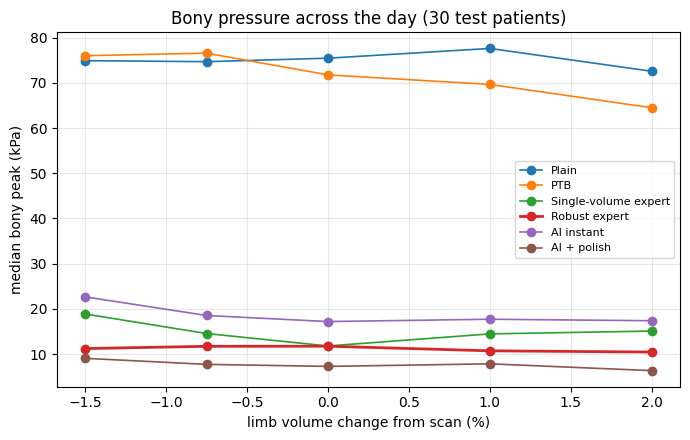

Which volume was each design's worst moment? (count of patients)
                        -1.50%  -0.75%  +0.00%  +1.00%  +2.00%
Plain                       13       6       4       2       5
PTB                         10       6       6       7       1
Single-volume expert        19       2       1       2       6
Robust expert               11       4       5       5       5
AI instant                  11       4       6       3       6
AI + polish                 14       3       4       5       4


In [8]:
fig, ax = plt.subplots(figsize=(7, 4.5))
x = [100 * v for v in VOLUME_CHANGES]
for name, r in RES.items():
    ax.plot(x, np.median(r['bony'], 0), 'o-', label=name, lw=2 if 'Robust' in name else 1.2)
ax.set_xlabel('limb volume change from scan (%)'); ax.set_ylabel('median bony peak (kPa)')
ax.set_title('Bony pressure across the day (30 test patients)'); ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/fig_day_profile.png', dpi=300); plt.show()

worst_vol = {n: np.bincount(r['bony'].argmax(1), minlength=NV) for n, r in RES.items()}
print('Which volume was each design\'s worst moment? (count of patients)')
print(' ' * 22 + ''.join(f'{100 * v:+7.2f}%' for v in VOLUME_CHANGES))
for n, c in worst_vol.items():
    print(f'{n:22s}' + ''.join(f'{x:8d}' for x in c))

## Pressure map for one patient across designs
- designs' worst moment and the patient's robust vs. single difference is close to median


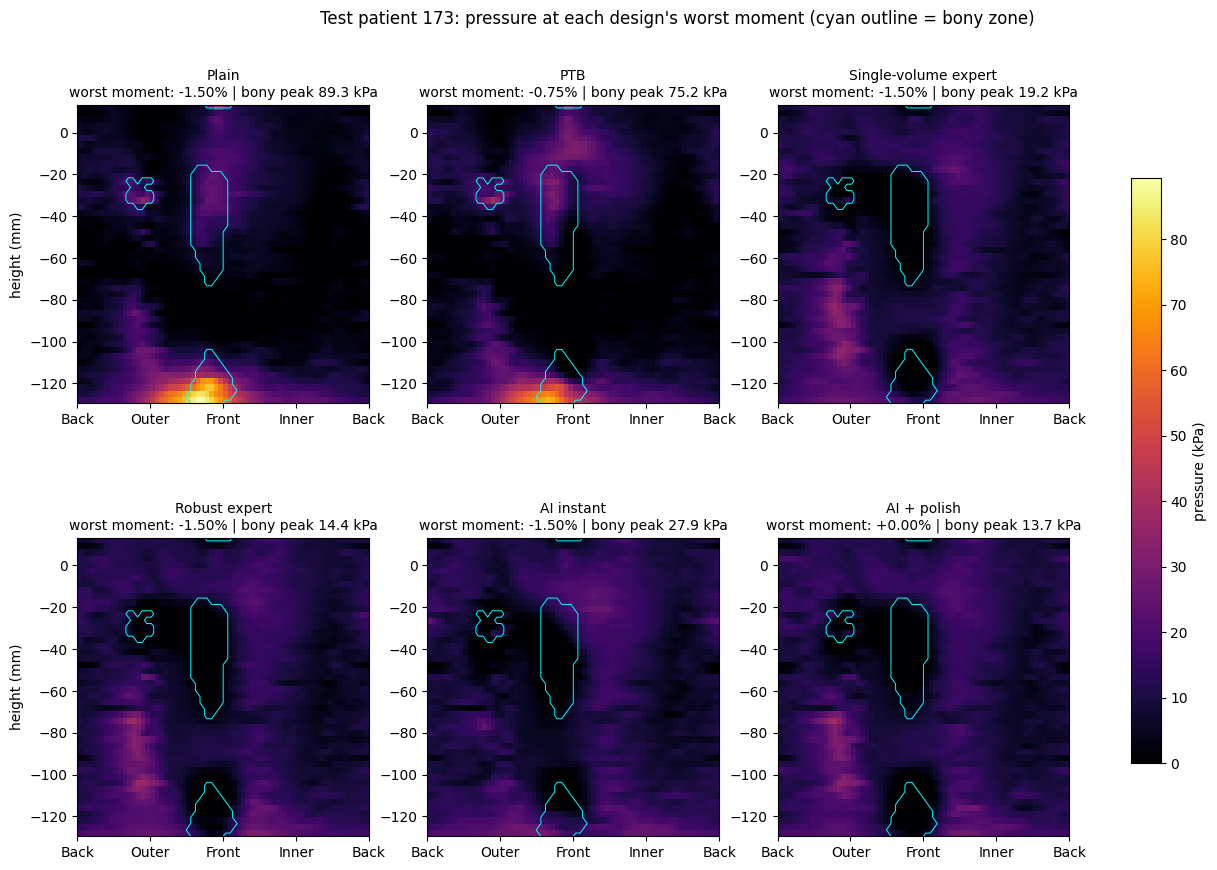

In [9]:
gap = RES['Single-volume expert']['worst'] - RES['Robust expert']['worst']
i = int(np.argsort(gap)[len(gap) // 2]); p = TE[i]
show = ['Plain', 'PTB', 'Single-volume expert', 'Robust expert', 'AI instant', 'AI + polish']
maps = []
for name in show:
    v = int(RES[name]['bony'][i].argmax())
    P, _, _ = simulate(torch.tensor([p], device=DEV), torch.tensor([v], device=DEV), DESIGNS[name][i:i + 1])
    maps.append((name, v, P[0].detach().cpu().numpy()))
vmax = max(m[2].max() for m in maps)
fig, axs = plt.subplots(2, 3, figsize=(16, 9.5))
plt.subplots_adjust(hspace=0.45)
for ax, (name, v, Pm) in zip(axs.flat, maps):
    im = ax.imshow(Pm, aspect='auto', cmap='inferno', vmin=0, vmax=vmax,
                   extent=[-180, 180, G['Z'][p][-1], G['Z'][p][0]])
    ax.contour(np.linspace(-180, 180, W), G['Z'][p], G['bony'][p], levels=[0.5], colors='cyan', linewidths=0.7)
    ax.set_title(f'{name}\nworst moment: {100 * VOLUME_CHANGES[v]:+.2f}% | bony peak {RES[name]["worst"][i]:.1f} kPa', fontsize=10)
    ax.set_xticks([-180, -90, 0, 90, 180], ['Back', 'Outer', 'Front', 'Inner', 'Back'])
    if ax in axs[:, 0]: ax.set_ylabel('height (mm)')
fig.colorbar(im, ax=axs, label='pressure (kPa)', shrink=0.8)
fig.suptitle(f'Test patient {p}: pressure at each design\'s worst moment (cyan outline = bony zone)')
plt.savefig(f'{FIG_DIR}/fig_pressure_maps.png', dpi=300, bbox_inches='tight'); plt.show()

## Stress test


In [10]:
STRESS_CHANGES = [-0.065, -0.04, +0.04, +0.05]

SKIN_FACES, PATELLA, TIBIA = D['skin_faces'], slice(23079, 29817), slice(29817, 51903)
BONE_MARGIN_MM = 5.0

def capped_volume(sv):
    m = trimesh.Trimesh(sv, SKIN_FACES, process=False)
    _, inv, cnt = np.unique(m.edges_sorted, axis=0, return_inverse=True, return_counts=True)
    b = m.edges[cnt[inv.reshape(-1)] == 1]
    c = sv[np.unique(b)].mean(0)
    cap = np.column_stack([b[:, 1], b[:, 0], np.full(len(b), len(sv))])
    return trimesh.Trimesh(np.vstack([sv, c]), np.vstack([SKIN_FACES, cap]), process=False).volume / 1000

def volume_version(sv, bone, target):
    thick, _ = cKDTree(bone).query(sv)
    wgt = np.clip(thick - BONE_MARGIN_MM, 0, None); wgt /= wgt.max()
    nrm = trimesh.Trimesh(sv, SKIN_FACES, process=False).vertex_normals
    v0 = capped_volume(sv)
    moved = lambda s: sv + np.maximum(s * wgt, -0.5 * thick)[:, None] * nrm
    err = lambda s: (capped_volume(moved(s)) - v0) / v0 - target
    s0, s1 = 0.0, 5.0 * np.sign(target); e0, e1 = err(s0), err(s1)
    for _ in range(8):
        if abs(e1) < 1e-4 or e1 == e0: break
        s0, s1, e0 = s1, s1 - e1 * (s1 - s0) / (e1 - e0), e1; e1 = err(s1)
    out = moved(s1)
    return out, (capped_volume(out) - v0) / v0

def radius_map(sv, axis, zs):
    x, y = sv[:, 0] - axis[0], sv[:, 1] - axis[1]
    th, r, z = np.arctan2(x, -y), np.hypot(x, y), sv[:, 2]
    keep = (z > zs.min() - 10) & (z < zs.max() + 10); th, r, z = th[keep], r[keep], z[keep]
    TH = np.concatenate([th - 2 * np.pi, th, th + 2 * np.pi])
    gt, gz = np.meshgrid(THETA, zs)
    R = griddata((TH, np.tile(z, 3)), np.tile(r, 3), (gt, gz), method='linear')
    if np.isnan(R).any():  # fill gaps with the nearest value
        R[np.isnan(R)] = griddata((TH, np.tile(z, 3)), np.tile(r, 3), (gt, gz), method='nearest')[np.isnan(R)]
    return R

NS = len(STRESS_CHANGES)
R_EXT_S = np.zeros((NP, NS, N_EXT, W), np.float32); T_S = np.zeros((NP, NS, H, W), np.float32)
Z0_S = np.zeros((NP, NS), np.float32); DZE_S = np.ones((NP, NS), np.float32)
achieved = np.zeros((len(TE), NS))
t0 = time.time()
for i, p in enumerate(TE):
    skin, bone = D['skin'][p, REF].astype(float), D['bone'][p].astype(float)
    Z = G['Z'][p].astype(float); z_top, z_bot = Z[0], Z[-1]
    band = (skin[:, 2] < z_top) & (skin[:, 2] > z_bot); axis = skin[band][:, :2].mean(0)
    z_ext = np.linspace(z_bot - 30.0, z_top + 60.0, N_EXT)
    for j, target in enumerate(STRESS_CHANGES):
        sv, got = volume_version(skin, bone, target); achieved[i, j] = got
        R_EXT_S[p, j] = np.nan_to_num(radius_map(sv, axis, z_ext), nan=0.0)
        Rv = radius_map(sv, axis, Z)
        gt, gz = np.meshgrid(THETA, Z)
        pts = np.stack([axis[0] + Rv * np.sin(gt), axis[1] - Rv * np.cos(gt), gz], -1).reshape(-1, 3)
        T_S[p, j] = cKDTree(bone).query(pts)[0].reshape(H, W)
        Z0_S[p, j], DZE_S[p, j] = z_ext[0], z_ext[1] - z_ext[0]
    if (i + 1) % 10 == 0:
        print(f'{i + 1}/{len(TE)} test patients | {time.time() - t0:.0f} s')
for j, target in enumerate(STRESS_CHANGES):
    print(f'target {target:+.1%}: got {np.median(achieved[:, j]):+.2%} median (range {achieved[:, j].min():+.2%} to {achieved[:, j].max():+.2%})')

R_EXT = torch.cat([R_EXT, gpu(R_EXT_S)], 1); T_ = torch.cat([T_, gpu(T_S)], 1)
Z0 = torch.cat([Z0, gpu(Z0_S)], 1); DZE = torch.cat([DZE, gpu(DZE_S)], 1)
STRESS_V = list(range(NV, NV + NS))

10/30 test patients | 74 s
20/30 test patients | 144 s
30/30 test patients | 219 s
target -6.5%: got -6.50% median (range -6.50% to -6.49%)
target -4.0%: got -4.00% median (range -4.01% to -4.00%)
target +4.0%: got +4.00% median (range +3.99% to +4.00%)
target +5.0%: got +5.00% median (range +4.99% to +5.01%)


In [11]:
STRESS = {name: evaluate(TE, off, vols=STRESS_V) for name, off in DESIGNS.items()}
print(f'{"Design":22s} | ' + ' | '.join(f'{100 * s:+5.1f}%' for s in STRESS_CHANGES) + ' | worst of stress')
for name, r in STRESS.items():
    print(f'{name:22s} | ' + ' | '.join(f'{x:6.1f}' for x in np.median(r['bony'], 0)) + f' | {np.median(r["worst"]):8.1f}')
p_s = wilcoxon(STRESS['Robust expert']['worst'], STRESS['Single-volume expert']['worst']).pvalue
d_s = STRESS['Robust expert']['worst'] - STRESS['Single-volume expert']['worst']
print(f'\nRobust vs single-volume under stress: median diff {np.median(d_s):+.1f} kPa, '
      f'robust better for {np.mean(d_s < 0):.0%}, Wilcoxon p = {p_s:.2g}')

Design                 |  -6.5% |  -4.0% |  +4.0% |  +5.0% | worst of stress
Plain                  |   82.4 |   83.9 |   70.0 |   66.6 |     91.5
PTB                    |   79.5 |   72.2 |   65.2 |   63.1 |     79.9
Single-volume expert   |   23.8 |   21.0 |   14.3 |   12.5 |     25.2
Robust expert          |   24.0 |   15.8 |   10.1 |    8.5 |     24.1
AI instant             |   27.6 |   26.0 |   13.5 |   14.7 |     30.2
AI + polish            |   19.4 |   15.4 |    8.5 |    7.9 |     20.6

Robust vs single-volume under stress: median diff -3.6 kPa, robust better for 73%, Wilcoxon p = 0.0013


## Liner friction as factor test


In [12]:
LINERS = {'Foam (main)': MU, 'Silicone': 0.37}
LINER = {}
for liner, mu in LINERS.items():
    LINER[liner] = {name: evaluate(TE, off, mu=mu) for name, off in DESIGNS.items()}
print(f'{"Design":22s} | ' + ' | '.join(f'{l:>12s}' for l in LINERS))
for name in DESIGNS:
    print(f'{name:22s} | ' + ' | '.join(f'{np.median(LINER[l][name]["worst"]):9.1f} kPa' for l in LINERS))
for liner in LINERS:
    d = LINER[liner]['Robust expert']['worst'] - LINER[liner]['Single-volume expert']['worst']
    print(f'{liner}: robust better than single-volume for {np.mean(d < 0):.0%} of patients '
          f'(p = {wilcoxon(LINER[liner]["Robust expert"]["worst"], LINER[liner]["Single-volume expert"]["worst"]).pvalue:.2g})')

Design                 |  Foam (main) |     Silicone
Plain                  |      80.3 kPa |     123.8 kPa
PTB                    |      78.0 kPa |     109.6 kPa
Single-volume expert   |      19.1 kPa |      61.8 kPa
Robust expert          |      13.4 kPa |      57.0 kPa
AI instant             |      22.7 kPa |      52.9 kPa
AI + polish            |      10.4 kPa |      52.9 kPa
Foam (main): robust better than single-volume for 90% of patients (p = 8.3e-07)
Silicone: robust better than single-volume for 67% of patients (p = 0.077)


## Sensitivity analysis to self-chosen values


In [13]:
def bony_zone(cutoff, frac=0.05):
    out = np.zeros_like(G['bony'])
    for p in range(NP):
        T, pt = G['T'][p, REF], G['pt'][p]
        b = (T < cutoff) & ~pt
        if b.sum() < frac * T.size:
            b = (T <= np.quantile(T[~pt], frac)) & ~pt
        out[p] = b
    return gpu(out, torch.bool)

SCENARIOS = {f'E = {E_TISSUE:g} kPa, cutoff 10 mm (main)': dict(),
             'E = 20 kPa': dict(E=20.0), 'E = 110 kPa': dict(E=110.0),
             'cutoff 8 mm': dict(bony=bony_zone(8.0)), 'cutoff 12 mm': dict(bony=bony_zone(12.0))}
show = ['PTB', 'Single-volume expert', 'Robust expert', 'AI instant']
SENS = {}
print(f'{"Scenario":32s} | ' + ' | '.join(f'{n[:14]:>14s}' for n in show) + ' | robust beats single')
for sc, kw in SCENARIOS.items():
    SENS[sc] = {n: evaluate(TE, DESIGNS[n], **kw)['worst'] for n in show}
    d = SENS[sc]['Robust expert'] - SENS[sc]['Single-volume expert']
    print(f'{sc:32s} | ' + ' | '.join(f'{np.median(SENS[sc][n]):10.1f} kPa' for n in show) + f' | {np.mean(d < 0):6.0%}')

Scenario                         |            PTB | Single-volume  |  Robust expert |     AI instant | robust beats single
E = 40 kPa, cutoff 10 mm (main)  |       78.0 kPa |       19.1 kPa |       13.4 kPa |       22.7 kPa |    90%
E = 20 kPa                       |       69.3 kPa |       45.7 kPa |       44.8 kPa |       39.9 kPa |    63%
E = 110 kPa                      |      134.4 kPa |       17.1 kPa |       17.8 kPa |       23.1 kPa |    63%
cutoff 8 mm                      |       78.0 kPa |       18.7 kPa |       12.0 kPa |       21.5 kPa |    90%
cutoff 12 mm                     |       78.0 kPa |       28.1 kPa |       24.3 kPa |       32.0 kPa |    73%


In [14]:
def objective_at(p, knobs, E, vols):
    B, nv = len(p), len(vols)
    pp = torch.as_tensor(p, device=DEV).repeat_interleave(nv); vv = torch.as_tensor(vols, device=DEV).repeat(B)
    P, _, _ = simulate(pp, vv, knobs_to_offset(knobs).repeat_interleave(nv, 0), E=E)
    bony = soft_max(P, BONY[pp]).view(B, nv); anyp = soft_max(P, torch.ones_like(BONY[pp])).view(B, nv)
    return (TAU * torch.logsumexp(bony / TAU, 1) + W_ANY * TAU * torch.logsumexp(anyp / TAU, 1)
            + W_TIDY * (knobs ** 2).mean((1, 2)))

def optimize_at(p, E, vols, steps=250, lr=0.3):
    raw = torch.zeros(len(p), NK_Z, NK_TH, device=DEV, requires_grad=True)
    opt = torch.optim.Adam([raw], lr=lr)
    for _ in range(steps):
        loss = objective_at(p, to_knobs(raw), E, vols).sum(); opt.zero_grad(); loss.backward(); opt.step()
    return to_knobs(raw.detach())

print(f'{"Stiffness":10s} | single (re-opt) | robust (re-opt) | robust better | p')
REOPT = {}
for E in [20.0, 110.0]:
    t0 = time.time()
    ks = optimize_at(TE, E, [REF]); kr = optimize_at(TE, E, list(range(NV)))
    ws = evaluate(TE, knobs_to_offset(ks), E=E)['worst']
    wr = evaluate(TE, knobs_to_offset(kr), E=E)['worst']
    REOPT[E] = (ws, wr)
    print(f'E = {E:5.0f}  | {np.median(ws):11.1f} kPa | {np.median(wr):11.1f} kPa | '
          f'{np.mean(wr < ws):12.0%} | {wilcoxon(wr, ws).pvalue:.2g}  ({time.time() - t0:.0f} s)')

Stiffness  | single (re-opt) | robust (re-opt) | robust better | p
E =    20  |        35.1 kPa |        24.9 kPa |          83% | 0.00087  (14 s)
E =   110  |        19.0 kPa |         9.6 kPa |          97% | 1.3e-08  (15 s)


In [15]:
def objective_mu(p, knobs, mu, vols):
    B, nv = len(p), len(vols)
    pp = torch.as_tensor(p, device=DEV).repeat_interleave(nv); vv = torch.as_tensor(vols, device=DEV).repeat(B)
    P, _, _ = simulate(pp, vv, knobs_to_offset(knobs).repeat_interleave(nv, 0), mu=mu)
    bony = soft_max(P, BONY[pp]).view(B, nv); anyp = soft_max(P, torch.ones_like(BONY[pp])).view(B, nv)
    return (TAU * torch.logsumexp(bony / TAU, 1) + W_ANY * TAU * torch.logsumexp(anyp / TAU, 1)
            + W_TIDY * (knobs ** 2).mean((1, 2)))

def optimize_mu(p, mu, vols, steps=250, lr=0.3):
    raw = torch.zeros(len(p), NK_Z, NK_TH, device=DEV, requires_grad=True)
    opt = torch.optim.Adam([raw], lr=lr)
    for _ in range(steps):
        loss = objective_mu(p, to_knobs(raw), mu, vols).sum(); opt.zero_grad(); loss.backward(); opt.step()
    return to_knobs(raw.detach())

MU_SIL = LINERS['Silicone']
ks = optimize_mu(TE, MU_SIL, [REF]); kr = optimize_mu(TE, MU_SIL, list(range(NV)))
ws = evaluate(TE, knobs_to_offset(ks), mu=MU_SIL)['worst']
wr = evaluate(TE, knobs_to_offset(kr), mu=MU_SIL)['worst']
print(f'Silicone re-optimized: single {np.median(ws):.1f} kPa | robust {np.median(wr):.1f} kPa | '
      f'robust better {np.mean(wr < ws):.0%} | p = {wilcoxon(wr, ws).pvalue:.2g}')

Silicone re-optimized: single 37.0 kPa | robust 30.7 kPa | robust better 83% | p = 6e-06


## Visualize learning curve


 35 limbs: 35.6, 31.1, 32.2 kPa | mean 33.0 | 29 s
 70 limbs: 28.3, 30.1, 28.6 kPa | mean 29.0 | 67 s
140 limbs: 24.3, 28.3, 26.6 kPa | mean 26.4 | 127 s


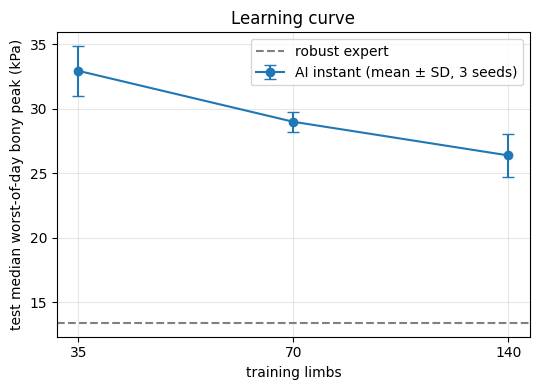

In [16]:
def mirror(t): return torch.roll(torch.flip(t, [-1]), 1, -1)
R_REF, R_EXT, T_, BONY, PT, PTB = [torch.cat([a, mirror(a)]) for a in (R_REF, R_EXT, T_, BONY, PT, PTB)]
Z_, Z0, DZE = [torch.cat([a, a]) for a in (Z_, Z0, DZE)]
Xn_all = torch.cat([Xn, mirror(Xn)])
K_ROB_ALL = torch.cat([gpu(EK['robust']), mirror(gpu(EK['robust']))])

def train_designer(train_ids, epochs1=600, epochs2=40, seed=0):
    torch.manual_seed(seed); np.random.seed(seed)
    net = SocketDesigner().to(DEV)
    nn.init.zeros_(net.head[-1].weight); nn.init.zeros_(net.head[-1].bias)
    tr = np.concatenate([train_ids, train_ids + NP]); nb = max(1, len(tr) // 28)
    opt = torch.optim.Adam(net.parameters(), lr=1e-3, weight_decay=1e-4)
    sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, epochs1)
    for _ in range(epochs1):
        net.train()
        for b in np.array_split(np.random.permutation(tr), nb):
            b = torch.as_tensor(b, device=DEV)
            loss = F.mse_loss(net(Xn_all[b]), K_ROB_ALL[b]); opt.zero_grad(); loss.backward(); opt.step()
        sch.step()
    def score(ids):
        net.eval()
        with torch.no_grad():
            k = net(Xn_all[torch.as_tensor(ids, device=DEV)])
        return np.median(evaluate(ids, knobs_to_offset(k))['worst'])
    opt = torch.optim.Adam(net.parameters(), lr=3e-4, weight_decay=1e-4)
    best, state = score(IDS['val']), {k: v.clone() for k, v in net.state_dict().items()}
    for _ in range(epochs2):
        net.train()
        for b in np.array_split(np.random.permutation(tr), nb):
            loss = objective(b, net(Xn_all[torch.as_tensor(b, device=DEV)])).mean(); opt.zero_grad(); loss.backward(); opt.step()
        s = score(IDS['val'])
        if s < best: best, state = s, {k: v.clone() for k, v in net.state_dict().items()}
    net.load_state_dict(state)
    return score(TE)

SIZES = [35, 70, 140]
rng = np.random.default_rng(0); order = rng.permutation(IDS['train'])
SEEDS = [0, 1, 2]
CURVE = {}
for n in SIZES:
    t0 = time.time()
    CURVE[n] = [train_designer(order[:n], seed=s) for s in SEEDS]
    print(f'{n:3d} limbs: ' + ', '.join(f'{c:.1f}' for c in CURVE[n]) +
          f' kPa | mean {np.mean(CURVE[n]):.1f} | {time.time() - t0:.0f} s')

plt.figure(figsize=(5.5, 4))
m = [np.mean(CURVE[n]) for n in SIZES]; s = [np.std(CURVE[n]) for n in SIZES]
plt.errorbar(SIZES, m, yerr=s, fmt='o-', capsize=4, label='AI instant (mean ± SD, 3 seeds)')
plt.axhline(np.median(RES['Robust expert']['worst']), ls='--', c='gray', label='robust expert')
plt.xscale('log'); plt.minorticks_off(); plt.xticks(SIZES, [str(x) for x in SIZES])
plt.xlabel('training limbs'); plt.ylabel('test median worst-of-day bony peak (kPa)')
plt.title('Learning curve'); plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig(f'{FIG_DIR}/fig_learning_curve.png', dpi=300); plt.show()

## Visualize worst-of-day bony peak for all designs and polish curve


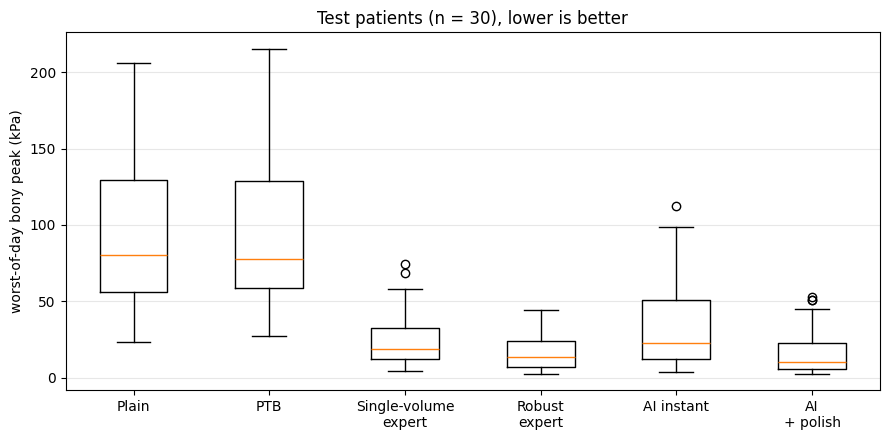

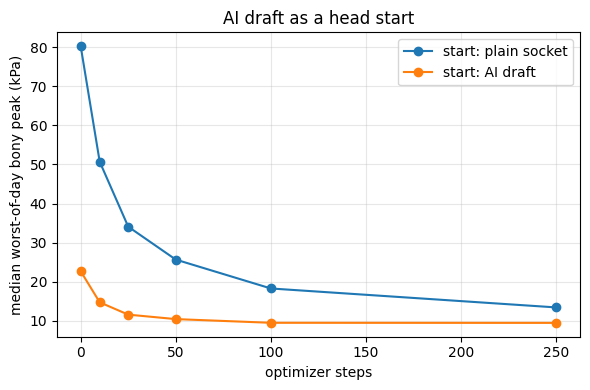

Figures saved in /content/drive/MyDrive/all-day-socket/figures : ['fig_day_profile.png', 'fig_learning_curve.png', 'fig_main_boxplot.png', 'fig_polish_curve.png', 'fig_pressure_maps.png']


In [17]:
names = list(RES)
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.boxplot([RES[n]['worst'] for n in names])
ax.set_xticks(range(1, len(names) + 1), [n.replace(' expert', '\nexpert').replace(' + ', '\n+ ') for n in names])
ax.set_ylabel('worst-of-day bony peak (kPa)'); ax.set_title('Test patients (n = 30), lower is better')
ax.grid(alpha=0.3, axis='y'); plt.tight_layout(); plt.savefig(f'{FIG_DIR}/fig_main_boxplot.png', dpi=300); plt.show()

steps = P3['check_steps']
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(steps, np.median(P3['from_plain'], 1), 'o-', label='start: plain socket')
ax.plot(steps, np.median(P3['from_ai'], 1), 'o-', label='start: AI draft')
ax.set_xlabel('optimizer steps'); ax.set_ylabel('median worst-of-day bony peak (kPa)')
ax.set_title('AI draft as a head start'); ax.legend(); ax.grid(alpha=0.3); plt.tight_layout()
plt.savefig(f'{FIG_DIR}/fig_polish_curve.png', dpi=300); plt.show()
print('Figures saved in', FIG_DIR, ':', sorted(os.listdir(FIG_DIR)))